# Tren Kasus Harian COVID-19 di Indonesia (2020–2023)
### Midterm Project — CAK4XBB3 Visualisasi Data

**Kelompok:** 4

| No | Nama | NIM |
|---|---|---|
| 1 | Nia Novela Ariandini | 2311102057 |
| 2 | Anisa Yasaroh | 2311102063 |
| 3 | Fitri Kusumaningtyas | 2311102068 |
| 4 | D'sharlendita Febianda Aurelia | 2311102069 |
| 5 | Muhammad Raafi Al Hafiidh | 2311102070 |

## Pendahuluan

Pandemi COVID-19 di Indonesia mengalami beberapa gelombang sejak pertama kali muncul pada Maret 2020. Setiap gelombang memiliki pola yang berbeda, baik dari jumlah kasus, jumlah kematian, maupun kecepatan penyebarannya. Pada periode tertentu, kasus meningkat secara perlahan, tetapi ada juga masa ketika jumlah kasus melonjak dalam waktu singkat hingga mencapai angka tertinggi.

Notebook ini membahas perkembangan kasus COVID-19 di Indonesia berdasarkan data harian kasus terkonfirmasi dan kematian, mulai dari Maret 2020 hingga Maret 2023, yaitu periode ketika pembaruan data mulai dihentikan. Melalui pengolahan dan analisis data tersebut, terdapat beberapa pertanyaan yang ingin dijawab, yaitu:

1. Kapan puncak-puncak gelombang COVID-19 terjadi di Indonesia, dan seberapa besar jumlah kasus pada setiap gelombang?
2. Apakah terdapat pola yang berulang, seperti pola musiman atau periodik, pada data kasus harian?
3. Seberapa cepat peningkatan kasus pada gelombang Delta dibandingkan dengan gelombang Omicron?
4. Bagaimana perkembangan kasus COVID-19 di Indonesia jika dibandingkan dengan negara-negara ASEAN lainnya?

Analisis ini diharapkan dapat memberikan gambaran mengenai pola penyebaran COVID-19 di Indonesia, perubahan jumlah kasus dari waktu ke waktu, serta perbandingan perkembangan pandemi Indonesia dengan negara lain di kawasan ASEAN.

## Table of Contents

<div class="alert alert-block alert-info" style="margin-top: 20px">

1. [Dataset](#0)<br>
2. [Downloading and Prepping Data](#2)<br>
3. [Visualizing Data using Matplotlib](#4)<br>
4. [Line Plot — Kasus Harian](#6)<br>
5. [Area Plot — Akumulasi Kematian](#8)<br>
6. [Multiple Time Series — Perbandingan ASEAN](#10)<br>
7. [Calendar Heatmap & Seasonal Plot](#12)<br>
8. [Analisis Tren: Moving Average](#14)<br>
9. [Analisis Tren: Exponential Fit](#16)<br>
10. [Identifikasi Komponen Time Series](#18)<br>
11. [Insight & Interpretasi](#20)<br>
12. [Deklarasi Penggunaan AI & Daftar Pustaka](#22)
</div>
<hr>

# Dataset

Dataset yang digunakan dalam analisis ini berasal dari COVID-19 Data Repository by the Center for Systems Science and Engineering (CSSE), Johns Hopkins University (JHU).

- Sumber: [GitHub JHU CSSE](https://github.com/CSSEGISandData/COVID-19?utm_source=chatgpt.com)
- File yang digunakan:
  - `time_series_covid19_confirmed_global.csv`: Data jumlah kasus positif COVID-19 secara kumulatif setiap harinya.
  - `time_series_covid19_deaths_global.csv`: Data jumlah kematian akibat COVID-19 secara kumulatif setiap harinya.

Data mencakup periode 22 Januari 2020 hingga 9 Maret 2023. Setelah tanggal tersebut, JHU menghentikan pembaruan data. Khusus Indonesia, data diperoleh dari laporan resmi pemerintah melalui Kemenkes dan Satgas COVID-19.

# Downloading and Prepping Data <a id="2"></a>

*Referensi: notebook 2_Visualization_Tools_1 (pandas Basics) dan 6_Visualization_in_Finance (bagian 2).*


In [ ]:
import numpy as np
import pandas as pd
import os
import warnings
warnings.filterwarnings('ignore')

### Membaca Dataset


In [ ]:
base_url = 'https://raw.githubusercontent.com/CSSEGISandData/COVID-19/master/csse_covid_19_data/csse_covid_19_time_series/'
file_confirmed = 'time_series_covid19_confirmed_global.csv'
file_deaths = 'time_series_covid19_deaths_global.csv'

if os.path.exists('data/' + file_confirmed):
    df_confirmed = pd.read_csv('data/' + file_confirmed)
    df_deaths = pd.read_csv('data/' + file_deaths)
    print('Data read from local folder data/')
else:
    df_confirmed = pd.read_csv(base_url + file_confirmed)
    df_deaths = pd.read_csv(base_url + file_deaths)
    print('Data downloaded from GitHub and read into a dataframe!')

Data downloaded from GitHub and read into a dataframe!


In [ ]:
df_confirmed.head()

,Province/State,Country/Region,Lat,Long,1/22/20,1/23/20,1/24/20,1/25/20,1/26/20,1/27/20,...,2/28/23,3/1/23,3/2/23,3/3/23,3/4/23,3/5/23,3/6/23,3/7/23,3/8/23,3/9/23
0,NaN,Afghanistan,33.93911,67.709953,0,0,0,0,0,0,...,209322,209340,209358,209362,209369,209390,209406,209436,209451,209451
1,NaN,Albania,41.15330,20.168300,0,0,0,0,0,0,...,334391,334408,334408,334427,334427,334427,334427,334427,334443,334457
2,NaN,Algeria,28.03390,1.659600,0,0,0,0,0,0,...,271441,271448,271463,271469,271469,271477,271477,271490,271494,271496
3,NaN,Andorra,42.50630,1.521800,0,0,0,0,0,0,...,47866,47875,47875,47875,47875,47875,47875,47875,47890,47890
4,NaN,Angola,-11.20270,17.873900,0,0,0,0,0,0,...,105255,105277,105277,105277,105277,105277,105277,105277,105288,105288


In [ ]:
# size of dataframe (rows, columns)
print(df_confirmed.shape)
print(df_deaths.shape)

(289, 1147)
(289, 1147)


### Pengolahan Format Dataset

Dataset awal menggunakan format wide format, yaitu setiap baris mewakili negara atau provinsi, sedangkan setiap kolom berisi tanggal dengan jumlah kasus kumulatif. Agar lebih mudah dianalisis sebagai data time series, format tersebut perlu diubah sehingga tanggal menjadi baris (index).

Tahapan pengolahannya sebagai berikut:

1. Memilih data tingkat negara dengan mengambil baris yang kolom `Province/State`-nya kosong.
2. Menghapus kolom yang tidak diperlukan, yaitu `Province/State`, `Lat`, dan `Long` menggunakan `drop()`.
3. Menjadikan `Country/Region` sebagai index menggunakan `set_index()`.
4. Menggunakan `transpose()` untuk mengubah posisi baris dan kolom sehingga tanggal menjadi baris dan negara menjadi kolom.

Hasil akhirnya berupa dataset dengan tanggal sebagai index, sehingga lebih mudah digunakan untuk analisis perkembangan kasus COVID-19 dari waktu ke waktu.

In [ ]:
def prep_data(df):
    df = df[df['Province/State'].isnull()].copy()
    df.drop(['Province/State', 'Lat', 'Long'], axis=1, inplace=True)
    df.set_index('Country/Region', inplace=True)
    df = df.transpose()
    df.index = pd.to_datetime(df.index, format='%m/%d/%y')
    df.index.name = 'Date'
    df.columns.name = None
    return df

df_cases = prep_data(df_confirmed)
df_death = prep_data(df_deaths)

df_cases.head()

,Afghanistan,Albania,Algeria,Andorra,Angola,Antarctica,Antigua and Barbuda,Argentina,Armenia,Austria,...,Uruguay,Uzbekistan,Vanuatu,Venezuela,Vietnam,West Bank and Gaza,Winter Olympics 2022,Yemen,Zambia,Zimbabwe
Date,,,,,,,,,,,,,,,,,,,,,
2020-01-22,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2020-01-23,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,2,0,0,0,0,0
2020-01-24,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,2,0,0,0,0,0
2020-01-25,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,2,0,0,0,0,0
2020-01-26,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,2,0,0,0,0,0


Dataset JHU CSSE mencakup 10 negara ASEAN. Namun, analisis ini difokuskan pada Indonesia, dengan memilih empat negara ASEAN lainnya sebagai pembanding untuk melihat perbedaan perkembangan kasus COVID-19 di kawasan Asia Tenggara

In [ ]:
asean = ['Indonesia', 'Malaysia', 'Philippines', 'Thailand', 'Vietnam']

df_cases = df_cases[asean]
df_death = df_death[asean]

df_cases.tail()

,Indonesia,Malaysia,Philippines,Thailand,Vietnam
Date,,,,,
2023-03-05,6737159,5043790,4077002,4728182,11526966
2023-03-06,6737303,5043978,4077109,4728182,11526966
2023-03-07,6737606,5044204,4077183,4728182,11526986
2023-03-08,6737918,5044439,4077302,4728182,11526994
2023-03-09,6738225,5044718,4077452,4728182,11526994


Data JHU berisi angka **kumulatif**. Kasus baru per hari didapat dari selisih hari ini dengan hari sebelumnya

In [ ]:
df_idn = pd.DataFrame({
    'Total Kasus': df_cases['Indonesia'],
    'Total Kematian': df_death['Indonesia'],
})

df_idn['Kasus Baru'] = df_idn['Total Kasus'].diff()
df_idn['Kematian Baru'] = df_idn['Total Kematian'].diff()

df_idn.head()

,Total Kasus,Total Kematian,Kasus Baru,Kematian Baru
Date,,,,
2020-01-22,0,0,NaN,NaN
2020-01-23,0,0,0.0,0.0
2020-01-24,0,0,0.0,0.0
2020-01-25,0,0,0.0,0.0
2020-01-26,0,0,0.0,0.0


### Cleaning: urutkan, cek duplikat, cek missing value

*Referensi: 6_Visualization_in_Finance*

In [ ]:
# check duplicated dates
df_idn.sort_index(inplace=True)
print('Duplicated dates :', df_idn.index.duplicated().sum())

# check null values
df_idn.isnull().sum()

Duplicated dates : 0


,0
Total Kasus,0
Total Kematian,0
Kasus Baru,1
Kematian Baru,1


Satu-satunya nilai kosong ada di baris pertama `Kasus Baru` dan `Kematian Baru` (hasil `diff()` tidak punya hari sebelumnya). Jadi, baris tersebut akan di drop.

In [ ]:
df_idn.dropna(inplace=True, axis=0)

print('Kasus baru negatif   :', (df_idn['Kasus Baru'] < 0).sum())
print('Kematian baru negatif:', (df_idn['Kematian Baru'] < 0).sum())

Kasus baru negatif   : 0
Kematian baru negatif: 0


Tidak ada nilai negatif. Indonesia baru melaporkan kasus pertama pada **2 Maret 2020**, jadi data sebelum tanggal itu hanya berisi angka nol. Jadi, potong data mulai **1 Maret 2020**.

In [ ]:
df_idn = df_idn.loc['2020-03-01':].astype(int)

print('Periode  :', df_idn.index.min().date(), 'sampai', df_idn.index.max().date())
print('Durasi   :', df_idn.index.max() - df_idn.index.min())
print('Observasi:', df_idn.shape[0], 'hari')

Periode  : 2020-03-01 sampai 2023-03-09
Durasi   : 1103 days 00:00:00
Observasi: 1104 hari


In [ ]:
df_idn.describe().astype(int)

,Total Kasus,Total Kematian,Kasus Baru,Kematian Baru
count,1104,1104,1104,1104
mean,3344571,90883,6103,145
std,2576282,66326,10311,293
min,0,0,0,0
25%,548124,17169,558,13
50%,4120253,135199,2787,45
75%,6057271,156622,5931,151
max,6738225,160941,64718,2069


## Descriptive Statistics

Berdasarkan hasil `describe()`, terdapat 1.104 observasi pada setiap variabel.

- Total Kasus: Rata-rata kasus kumulatif mencapai 3.344.571, dengan maksimum 6.738.225 kasus.
- Total Kematian: Rata-rata kematian kumulatif sebesar 90.883 jiwa, dengan maksimum 160.941 jiwa.
- Kasus Baru: Rata-rata sekitar 6.103 kasus per hari, tetapi nilai maksimumnya mencapai 64.718 kasus. Perbedaan ini menunjukkan adanya beberapa lonjakan kasus yang cukup tinggi selama pandemi.
- Kematian Baru: Rata-rata sekitar 145 jiwa per hari, sedangkan nilai maksimumnya mencapai 2.069 jiwa. Hal ini menunjukkan adanya fluktuasi kematian harian yang cukup besar.

Secara keseluruhan, data menunjukkan bahwa kasus dan kematian COVID-19 mengalami fluktuasi yang cukup tinggi selama periode pengamatan.

# Visualizing Data using Matplotlib <a id="4"></a>

*Referensi: 2_Visualization_Tools_1 (Matplotlib.Pyplot dan style ggplot).*

In [ ]:
%matplotlib inline

import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns

mpl.style.use(['ggplot'])

print('Matplotlib version: ', mpl.__version__)

Matplotlib version:  3.10.0


# Line Plot — Kasus Harian Indonesia <a id="6"></a>

*Referensi: 2_Visualization_Tools_1 (Line Plots, `plt.annotate`).*

Line plot digunakan untuk melihat tren kasus harian COVID-19, termasuk pola kenaikan, penurunan, dan puncak gelombang. Puncak terbesar kemudian akan ditandai dengan anotasi pada grafik.

In [ ]:
peak_delta = df_idn.loc['2021-06':'2021-09', 'Kasus Baru']
peak_omicron = df_idn.loc['2022-01':'2022-04', 'Kasus Baru']

print('Puncak Delta  :', peak_delta.idxmax().date(), '->', peak_delta.max(), 'kasus')
print('Puncak Omicron:', peak_omicron.idxmax().date(), '->', peak_omicron.max(), 'kasus')

Puncak Delta  : 2021-07-15 -> 56757 kasus
Puncak Omicron: 2022-02-16 -> 64718 kasus


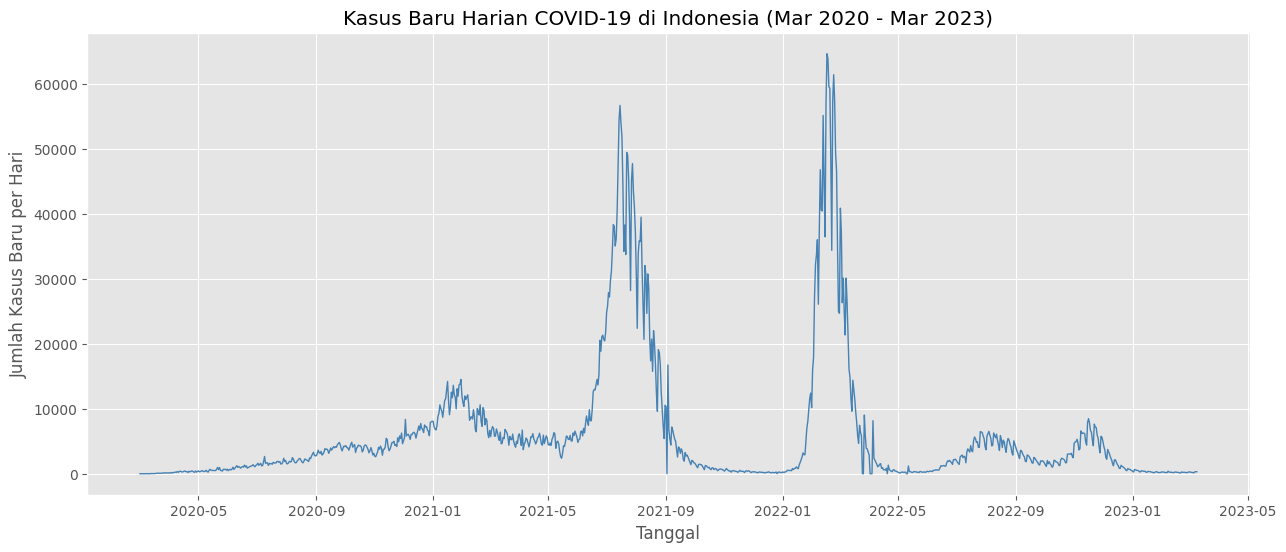

In [ ]:
plt.figure(figsize=(15, 6))
plt.plot(df_idn.index, df_idn['Kasus Baru'], color='steelblue', linewidth=1)

plt.title('Kasus Baru Harian COVID-19 di Indonesia (Mar 2020 - Mar 2023)')
plt.ylabel('Jumlah Kasus Baru per Hari')
plt.xlabel('Tanggal')

plt.show()

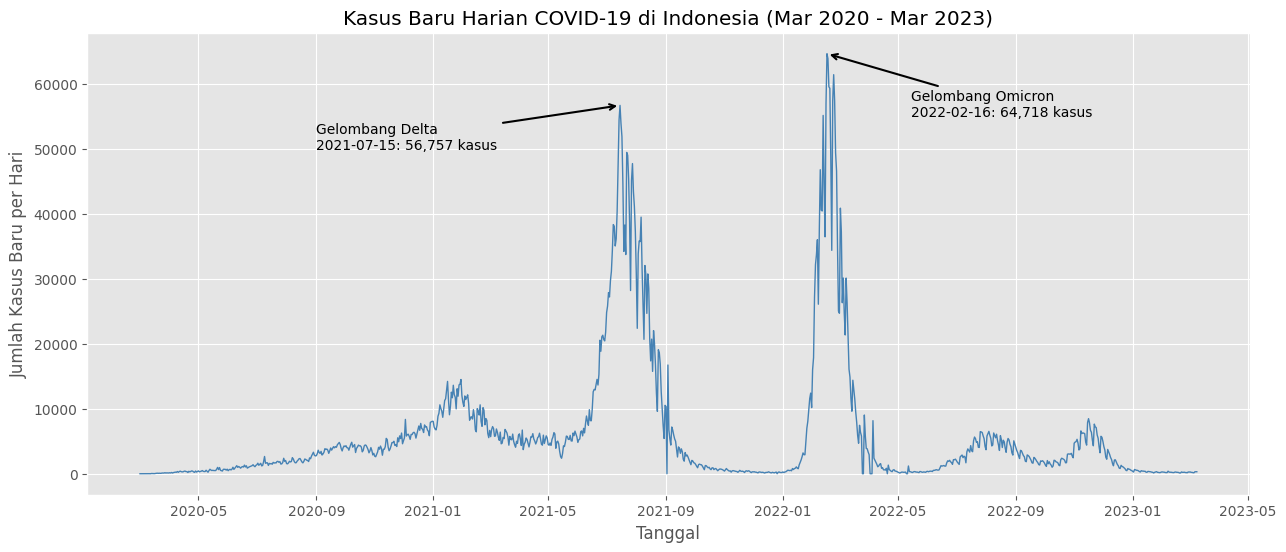

In [ ]:
plt.figure(figsize=(15, 6))
plt.plot(df_idn.index, df_idn['Kasus Baru'], color='steelblue', linewidth=1)

plt.title('Kasus Baru Harian COVID-19 di Indonesia (Mar 2020 - Mar 2023)')
plt.ylabel('Jumlah Kasus Baru per Hari')
plt.xlabel('Tanggal')


# Beri anotasi pada dua gelombang terbesar.
plt.annotate('Gelombang Delta\n' + str(peak_delta.idxmax().date()) + ': ' + format(peak_delta.max(), ',') + ' kasus',
             xy=(peak_delta.idxmax(), peak_delta.max()),
             xytext=(pd.Timestamp('2020-09-01'), 50000),
             xycoords='data',
             arrowprops=dict(arrowstyle='->', connectionstyle='arc3', color='black', lw=1.5)
            )

plt.annotate('Gelombang Omicron\n' + str(peak_omicron.idxmax().date()) + ': ' + format(peak_omicron.max(), ',') + ' kasus',
             xy=(peak_omicron.idxmax(), peak_omicron.max()),
             xytext=(pd.Timestamp('2022-05-15'), 55000),
             xycoords='data',
             arrowprops=dict(arrowstyle='->', connectionstyle='arc3', color='black', lw=1.5)
            )

plt.show()


1.   Gelombang Delta: Periode lonjakan kasus COVID-19 akibat penyebaran varian Delta yang terjadi sekitar Juni–Agustus 2021.
2.   Gelombang Omicron: Periode lonjakan kasus akibat penyebaran varian Omicron yang terjadi sekitar Januari–Maret 2022.




Dari line plot, terlihat dua lonjakan kasus terbesar, yaitu gelombang Delta pada Juli 2021 dan Omicron pada Februari 2022. Gelombang awal 2021 (Januari–Februari) terlihat lebih kecil, sedangkan setelah Maret 2022 masih terdapat dua lonjakan yang lebih rendah, yaitu sekitar Agustus dan November 2022.


Selain itu, garis grafik terlihat bergerigi dengan pola yang berulang setiap minggu.

Terdapat juga beberapa titik yang menunjukkan angka nol di tengah periode lonjakan kasus, seperti pada awal September 2021. Hal ini harus diperiksa lebih lanjut.

In [ ]:
zero_days = df_idn.loc['2020-04-01':'2022-12-31']
zero_days = zero_days[zero_days['Kasus Baru'] == 0]
print(zero_days['Kasus Baru'])

# Apa yang terjadi sekitar 2 September 2021?
df_idn.loc['2021-08-30':'2021-09-04', ['Kasus Baru']]

Date
2021-09-02    0
2021-12-26    0
2022-03-25    0
2022-03-26    0
2022-04-02    0
2022-04-03    0
2022-04-04    0
2022-04-20    0
2022-05-10    0
2022-05-11    0
Name: Kasus Baru, dtype: int64


,Kasus Baru
Date,
2021-08-30,5436
2021-08-31,10534
2021-09-01,10337
2021-09-02,0
2021-09-03,16752
2021-09-04,6727


Pada 2 September 2021 tercatat 0 kasus baru, kemudian meningkat tajam menjadi 16.752 kasus pada 3 September 2021. Pola ini mengindikasikan adanya anomali pelaporan, kemungkinan akibat keterlambatan pencatatan yang kemudian digabungkan pada hari berikutnya. Dengan demikian, angka nol tersebut belum tentu menunjukkan tidak adanya penularan COVID-19.

# Area Plot — Akumulasi Kematian <a id="8"></a>

*Referensi: 2_Visualization_Tools_1 (Area Plots, `kind='area'`, parameter `alpha`).*

Area plot digunakan untuk menggambarkan akumulasi total kematian COVID-19 di Indonesia dari waktu ke waktu. Grafik ini dilengkapi dengan penanda pada saat jumlah kematian kumulatif melewati 50 ribu, 100 ribu, dan 150 ribu jiwa. Penanda tersebut berfungsi sebagai titik acuan untuk memperjelas perkembangan akumulasi kematian dan melihat seberapa cepat jumlahnya meningkat selama pandemi.

In [ ]:
milestones = [50000, 100000, 150000]

for m in milestones:
    date_m = df_idn[df_idn['Total Kematian'] >= m].index[0]
    print(format(m, ','), 'kematian tercapai pada', date_m.date())

50,000 kematian tercapai pada 2021-05-28
100,000 kematian tercapai pada 2021-08-04
150,000 kematian tercapai pada 2022-03-06


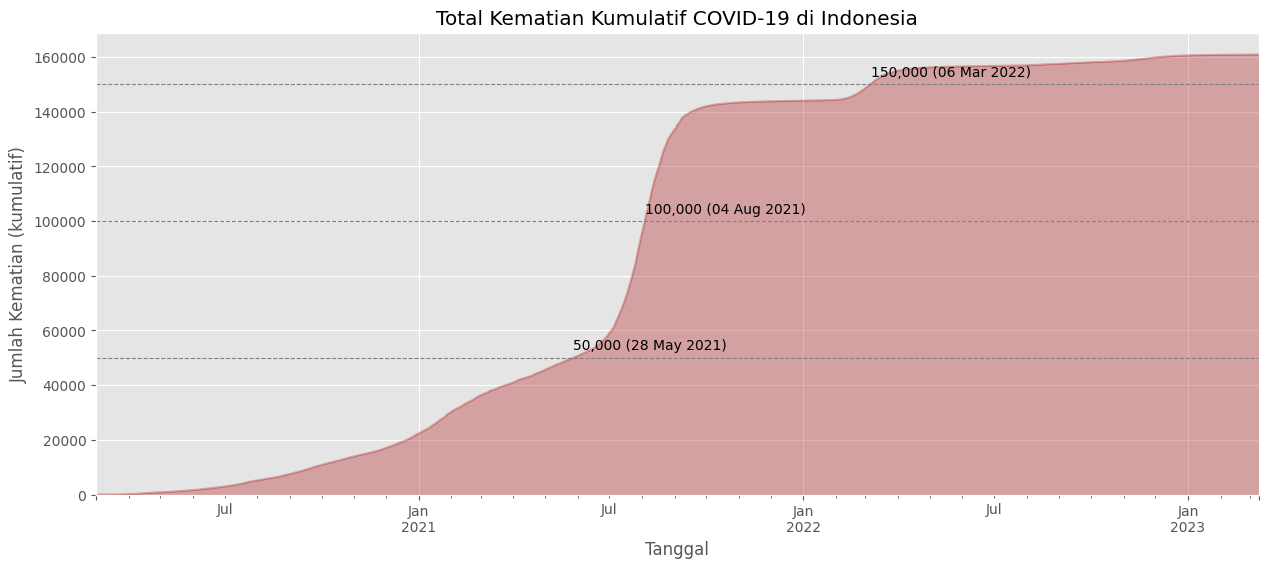

In [ ]:
ax = df_idn['Total Kematian'].plot(kind='area',
                                   alpha=0.35,
                                   color='firebrick',
                                   figsize=(15, 6))

ax.set_title('Total Kematian Kumulatif COVID-19 di Indonesia')
ax.set_ylabel('Jumlah Kematian (kumulatif)')
ax.set_xlabel('Tanggal')

# Beri penanda pada titik-titik pencapaian
for m in milestones:
    date_m = df_idn[df_idn['Total Kematian'] >= m].index[0]
    ax.axhline(m, color='gray', linestyle='--', linewidth=0.8)
    ax.text(date_m, m + 3000, format(m, ',') + ' (' + date_m.strftime('%d %b %Y') + ')', fontsize=10)

plt.show()

Peningkatan kematian paling tajam terjadi pada Juli–Agustus 2021, ketika jumlah kematian naik dari 50 ribu (28 Mei 2021) menjadi 100 ribu (4 Agustus 2021) dalam sekitar dua bulan. Sementara itu, kenaikan dari 100 ribu menjadi 150 ribu membutuhkan waktu sekitar tujuh bulan. Meskipun kasus harian saat gelombang Omicron lebih tinggi, pertambahan kematian tidak secepat periode sebelumnya. Setelah Maret 2022, grafik cenderung mendatar, menunjukkan penambahan kematian yang semakin kecil.

# Multiple Time Series — Perbandingan 5 Negara ASEAN <a id="10"></a>

*Referensi: 2_Visualization_Tools_1 (Line Plots untuk beberapa negara, `plt.text`).*

Membandingkan total kasus COVID-19 kumulatif pada lima negara ASEAN.

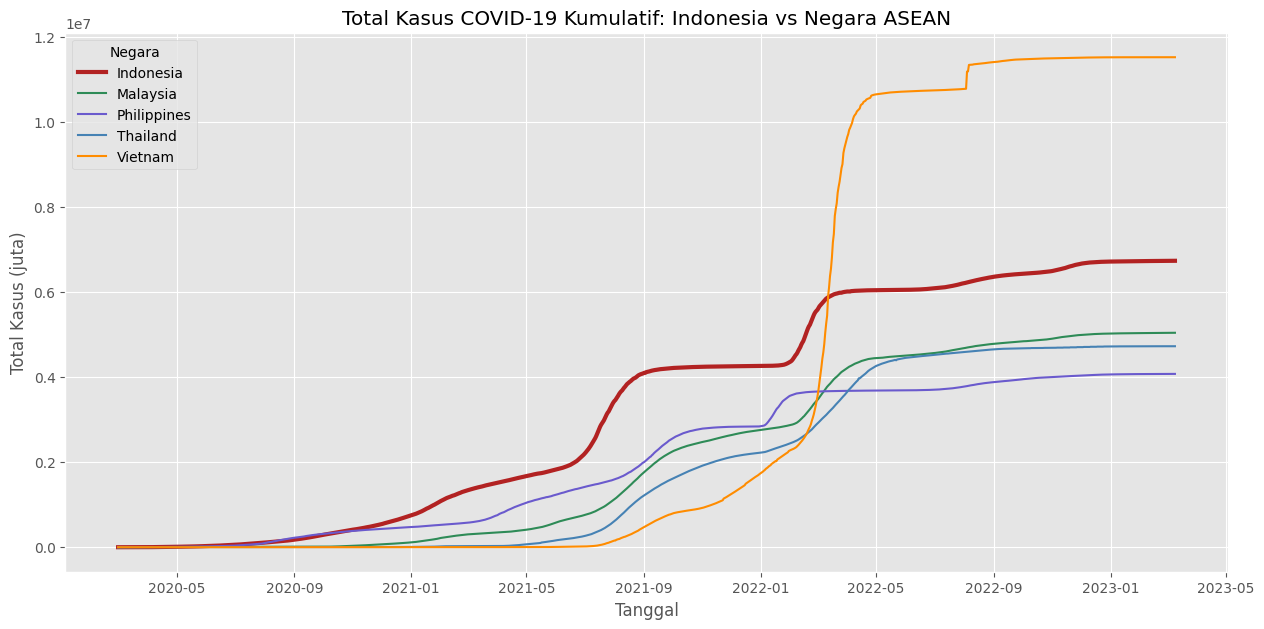

In [ ]:
df_cases_m = df_cases.loc['2020-03-01':]

colors = {'Indonesia': 'firebrick', 'Vietnam': 'darkorange', 'Malaysia': 'seagreen',
          'Thailand': 'steelblue', 'Philippines': 'slateblue'}

plt.figure(figsize=(15, 7))

for country in asean:
    lw = 3 if country == 'Indonesia' else 1.5
    plt.plot(df_cases_m.index, df_cases_m[country],
             color=colors[country], linewidth=lw, label=country)

plt.title('Total Kasus COVID-19 Kumulatif: Indonesia vs Negara ASEAN')
plt.ylabel('Total Kasus (juta)')
plt.xlabel('Tanggal')
plt.legend(title='Negara')

plt.show()

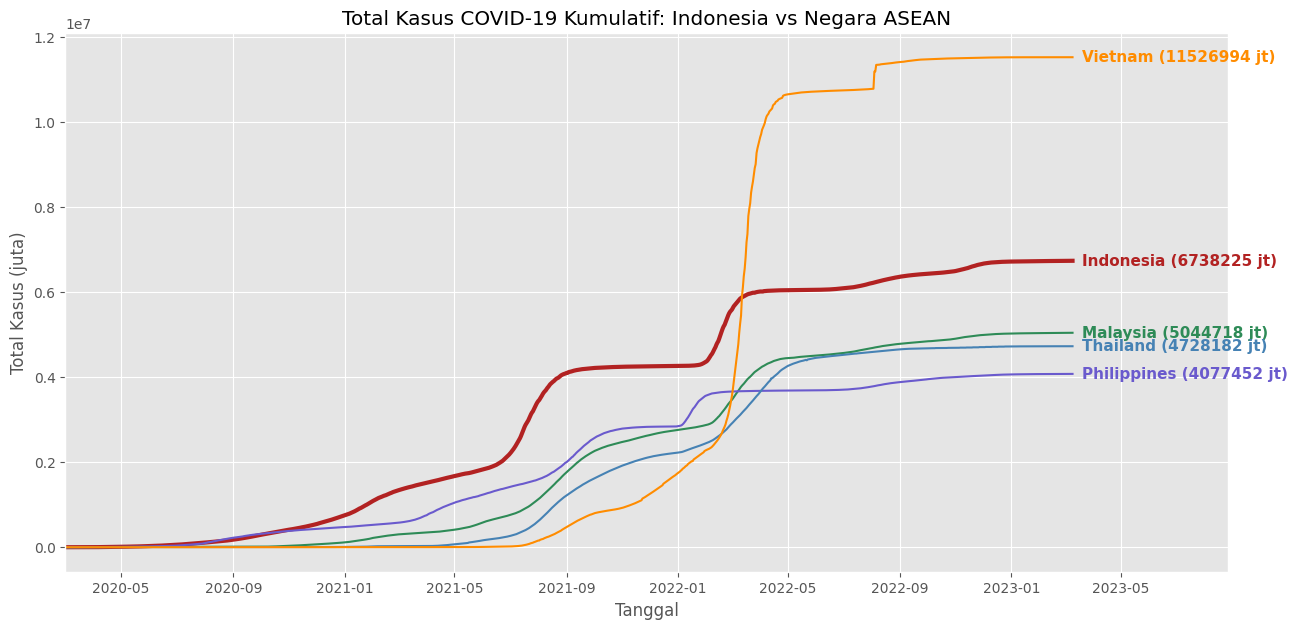

In [ ]:
# Penambahan direct labeling agar lebih rapi

df_cases_m = df_cases.loc['2020-03-01':]

colors = {'Indonesia': 'firebrick', 'Vietnam': 'darkorange', 'Malaysia': 'seagreen',
          'Thailand': 'steelblue', 'Philippines': 'slateblue'}

plt.figure(figsize=(15, 7))

for country in asean:
    lw = 3 if country == 'Indonesia' else 1.5
    plt.plot(df_cases_m.index, df_cases_m[country], color=colors[country], linewidth=lw)

    # direct labeling di ujung garis sebelah kanan
    last_date = df_cases_m.index[-1]
    last_value = df_cases_m[country].iloc[-1]
    offset = {'Malaysia': 0.15, 'Thailand': -0.15}.get(country, 0)
    plt.text(last_date + pd.Timedelta(days=10), last_value + offset,
             country + ' (' + str(round(last_value, 2)) + ' jt)',
             color=colors[country], fontsize=11, va='center', fontweight='bold')

plt.title('Total Kasus COVID-19 Kumulatif: Indonesia vs Negara ASEAN')
plt.ylabel('Total Kasus (juta)')
plt.xlabel('Tanggal')
plt.xlim(df_cases_m.index[0], df_cases_m.index[-1] + pd.Timedelta(days=170))

plt.show()

Sejak akhir 2020 sampai awal 2022, Indonesia memiliki kasus kumulatif terbanyak di antara lima negara ini. Vietnam, yang hampir nol kasus sampai pertengahan 2021, melonjak sangat tajam dan **menyalip Indonesia** pada Maret 2022.


---


Cek tanggal Vietnam menyalip Indonesia:

In [ ]:
vn_over_id = df_cases.loc['2021-01-01':]
vn_over_id = vn_over_id[vn_over_id['Vietnam'] > vn_over_id['Indonesia']]

tanggal = vn_over_id.index[0]
kasus_vietnam = vn_over_id.loc[tanggal, 'Vietnam']
kasus_indonesia = vn_over_id.loc[tanggal, 'Indonesia']

print('Tanggal Vietnam menyalip Indonesia:', tanggal.strftime('%d %B %Y'))
print('Total kasus kumulatif Vietnam:', kasus_vietnam)
print('Total kasus kumulatif Indonesia:', kasus_indonesia)

Tanggal Vietnam menyalip Indonesia: 12 March 2022
Total kasus kumulatif Vietnam: 5903147
Total kasus kumulatif Indonesia: 5878910


# Calendar Heatmap & Seasonal Plot <a id="12"></a>

*Referensi: 4_Exploratory_Data_Analysis (`pivot_table`, `sns.heatmap`) dan 3_Visualization_Tools_2 (`groupby`).*

### Calendar heatmap (Tahun × Bulan)

Visualisasi ini digunakan untuk melihat jumlah kasus baru COVID-19 di Indonesia berdasarkan bulan dan tahun. Data dikelompokkan berdasarkan tahun dan bulan, kemudian dijumlahkan menggunakan `pivot_table` — seperti `pivot_table` pada notebook EDA untuk ditampilkan dalam bentuk heatmap. Perbedaan warna menunjukkan tinggi rendahnya jumlah kasus pada setiap bulan.

In [ ]:
df_idn['Tahun'] = df_idn.index.year
df_idn['Bulan'] = df_idn.index.month
df_idn['Hari'] = df_idn.index.dayofweek

monthly = df_idn.pivot_table(index='Tahun', columns='Bulan', values='Kasus Baru', aggfunc='sum')
monthly.columns = ['Jan', 'Feb', 'Mar', 'Apr', 'Mei', 'Jun', 'Jul', 'Agu', 'Sep', 'Okt', 'Nov', 'Des']
monthly

,Jan,Feb,Mar,Apr,Mei,Jun,Jul,Agu,Sep,Okt,Nov,Des
Tahun,,,,,,,,,,,,
2020,NaN,NaN,1528.0,8590.0,16355.0,29912.0,51991.0,66420.0,112212.0,123080.0,128795.0,204315.0
2021,335116.0,256320.0,177078.0,156656.0,153335.0,356569.0,1231386.0,680143.0,125303.0,29254.0,12051.0,6311.0
2022,90650.0,1211078.0,448370.0,33978.0,8177.0,33487.0,118638.0,151710.0,72816.0,61455.0,171765.0,54971.0
2023,10201.0,6030.0,2179.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**Dari tabel terlihat:**

2020 Januari–Februari: kosong karena data dimulai pada 1 Maret 2020.



2023 April–Desember: kosong karena data JHU CSSE berakhir pada 9 Maret 2023.

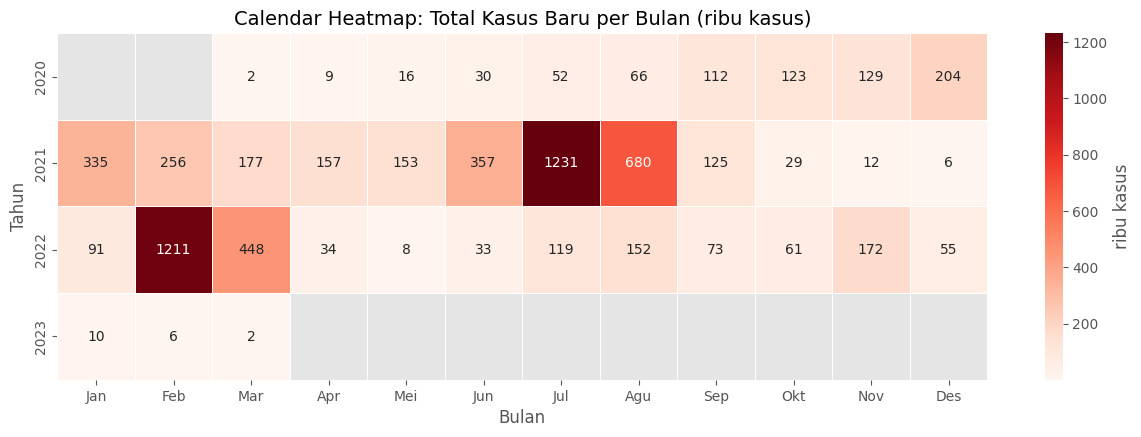

In [ ]:
f, ax = plt.subplots(figsize=(15, 4.5))
plt.title('Calendar Heatmap: Total Kasus Baru per Bulan (ribu kasus)', y=1, size=14)

sns.heatmap(monthly / 1000,
            annot=True,
            fmt='.0f',
            cmap='Reds',
            linewidths=0.5,
            linecolor='white',
            cbar_kws={'label': 'ribu kasus'})

plt.ylabel('Tahun')
plt.xlabel('Bulan')
plt.grid(False)
plt.show()

Sel dengan warna paling gelap terdapat pada Juli 2021 dan Februari 2022, dengan masing-masing sekitar 1,2 juta kasus baru. Puncak kasus tidak terjadi pada bulan yang sama setiap tahunnya. Hal ini terlihat dari tingginya kasus pada Juli 2021, sedangkan Juli 2022 relatif rendah

### Seasonal plot (pola mingguan)

Line plot sebelumnya menunjukkan pola grafik yang bergerigi. Untuk mengetahui apakah terdapat pola berulang setiap minggu, dilakukan pengelompokan data berdasarkan hari dalam seminggu menggunakan groupby(), kemudian dihitung rata-rata kasus baru dan ditampilkan dalam bentuk diagram batang (bar plot).

In [ ]:
nama_hari = ['Senin', 'Selasa', 'Rabu', 'Kamis', 'Jumat', 'Sabtu', 'Minggu']

df_weekday = df_idn.groupby('Hari')['Kasus Baru'].mean()
df_weekday.index = nama_hari
print(df_weekday.round(0))

Senin     4816.0
Selasa    6243.0
Rabu      6596.0
Kamis     6679.0
Jumat     6567.0
Sabtu     6299.0
Minggu    5528.0
Name: Kasus Baru, dtype: float64


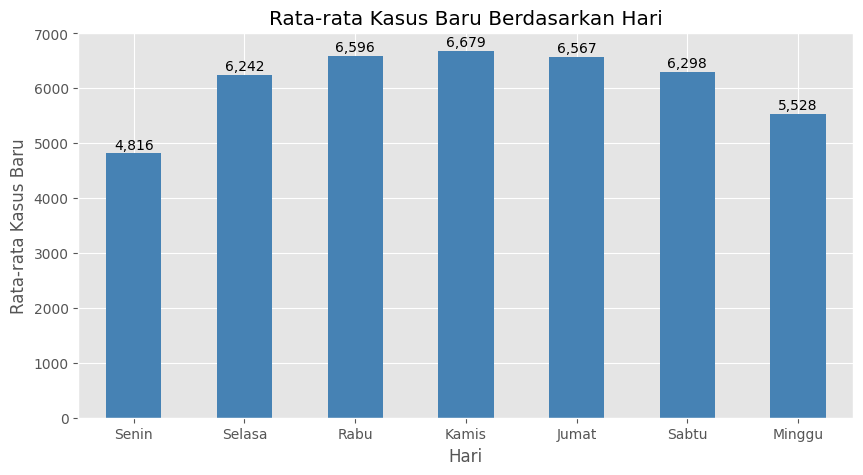

Kasus hari Senin lebih rendah 27.9 % dibanding Kamis


In [ ]:
ax = df_weekday.plot(kind='bar', figsize=(10, 5), color='steelblue', rot=0)

ax.set_title('Rata-rata Kasus Baru Berdasarkan Hari')
ax.set_ylabel('Rata-rata Kasus Baru')
ax.set_xlabel('Hari')

# Menampilkan angka di atas batang
for i, value in enumerate(df_weekday):
    ax.text(i, value + 80, format(int(value), ','), ha='center')

plt.show()

# Membandingkan rata-rata kasus hari Senin dan Kamis
selisih = (df_weekday['Kamis'] - df_weekday['Senin']) / df_weekday['Kamis'] * 100

print('Kasus hari Senin lebih rendah', round(selisih, 1), '% dibanding Kamis')

Terlihat pola mingguan yang jelas, dengan Senin memiliki rata-rata kasus terendah, disusul Minggu, sedangkan Rabu–Jumat paling tinggi. Pola ini kemungkinan dipengaruhi oleh siklus pelaporan, seperti berkurangnya pemeriksaan dan pencatatan pada akhir pekan.

Untuk melihat apakah pola tersebut berulang setiap tahun, dibuat seasonal plot dengan setiap garis mewakili satu tahun. Nilai dinormalisasi terhadap rata-rata tahunan (100 = rata-rata).

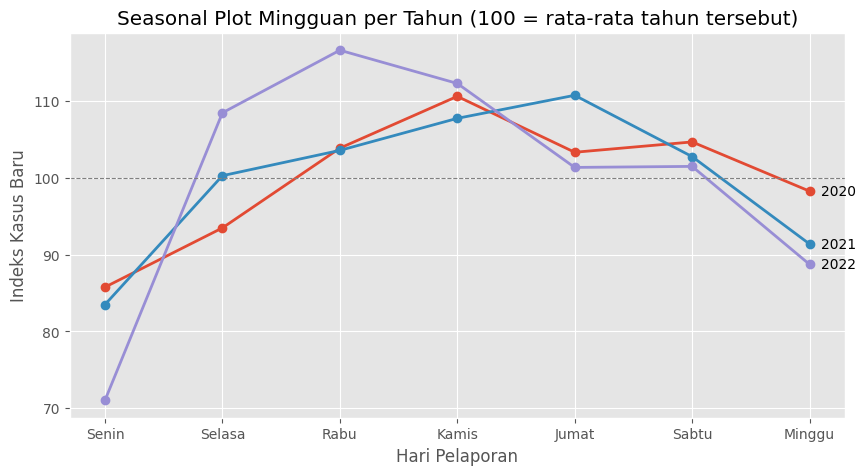

In [ ]:
df_season = df_idn.loc['2020-06':'2022-12'].groupby(
    ['Tahun', 'Hari'])['Kasus Baru'].mean().unstack(0)


# Normalisasi rata-rata setiap tahun
df_season = df_season / df_season.mean() * 100
df_season.index = nama_hari

plt.figure(figsize=(10, 5))
for year in df_season.columns:
    plt.plot(df_season.index, df_season[year], marker='o', linewidth=2)
    plt.text(6.1, df_season[year].iloc[-1], str(year), va='center')   # direct label

plt.axhline(100, color='gray', linestyle='--', linewidth=0.8)
plt.title('Seasonal Plot Mingguan per Tahun (100 = rata-rata tahun tersebut)')
plt.ylabel('Indeks Kasus Baru')
plt.xlabel('Hari Pelaporan')
plt.show()

Pada setiap tahun (2020, 2021, 2022) garis turun di Minggu–Senin dan naik lagi di pertengahan minggu.

# Analisis Tren: Moving Average <a id="14"></a>

*Referensi: 6_Visualization_in_Finance (bagian 9, `rolling(7)`).*

Moving average menghaluskan noise harian dengan merata-ratakan nilai dalam sebuah *window*. Membandingkan dua ukuran window:
- **7 hari** — pas satu siklus mingguan, sehingga efek hari pelaporan (Senin rendah) ikut hilang.
- **30 hari** — kurang lebih satu bulan, menampilkan arah gelombang secara umum.

In [ ]:
df_idn['MA 7 Hari'] = df_idn['Kasus Baru'].rolling(7).mean()
df_idn['MA 30 Hari'] = df_idn['Kasus Baru'].rolling(30).mean()

df_idn[['Kasus Baru', 'MA 7 Hari', 'MA 30 Hari']].head(10)

,Kasus Baru,MA 7 Hari,MA 30 Hari
Date,,,
2020-03-01,0,NaN,NaN
2020-03-02,2,NaN,NaN
2020-03-03,0,NaN,NaN
2020-03-04,0,NaN,NaN
2020-03-05,0,NaN,NaN
2020-03-06,2,NaN,NaN
2020-03-07,0,0.571429,NaN
2020-03-08,2,0.857143,NaN
2020-03-09,13,2.428571,NaN


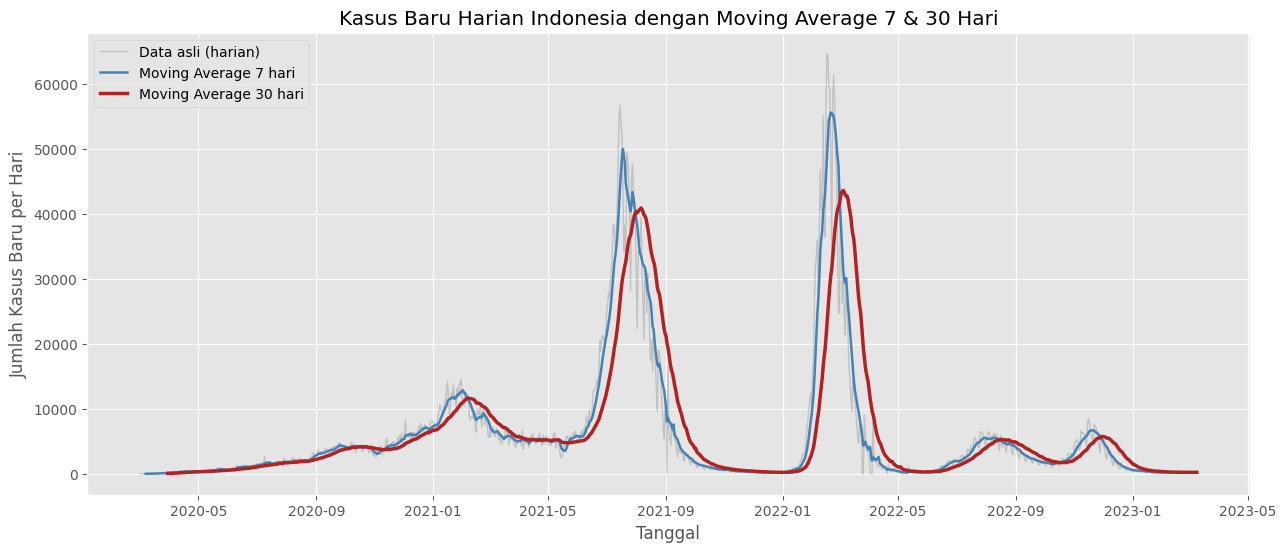

In [ ]:
plt.figure(figsize=(15, 6))

plt.plot(df_idn.index, df_idn['Kasus Baru'], color='gray', alpha=0.35, linewidth=1, label='Data asli (harian)')
plt.plot(df_idn.index, df_idn['MA 7 Hari'], color='steelblue', linewidth=1.8, label='Moving Average 7 hari')
plt.plot(df_idn.index, df_idn['MA 30 Hari'], color='firebrick', linewidth=2.5, label='Moving Average 30 hari')

plt.title('Kasus Baru Harian Indonesia dengan Moving Average 7 & 30 Hari')
plt.ylabel('Jumlah Kasus Baru per Hari')
plt.xlabel('Tanggal')
plt.legend(loc='upper left')
plt.show()

Zoom gelombang Delta (Juni–September 2021).

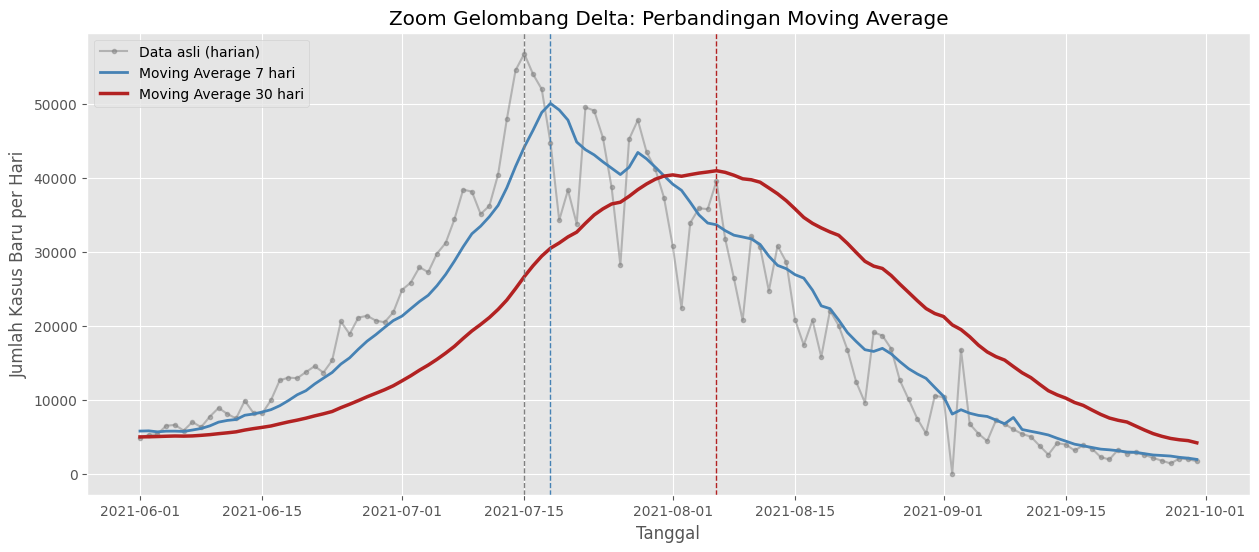

In [ ]:
zoom_delta = df_idn.loc['2021-06-01':'2021-09-30']

plt.figure(figsize=(15, 6))

plt.plot(zoom_delta.index, zoom_delta['Kasus Baru'], color='gray',
         alpha=0.5, marker='.', label='Data asli (harian)')
plt.plot(zoom_delta.index, zoom_delta['MA 7 Hari'], color='steelblue',
         linewidth=2, label='Moving Average 7 hari')
plt.plot(zoom_delta.index, zoom_delta['MA 30 Hari'], color='firebrick',
         linewidth=2.5, label='Moving Average 30 hari')

# Tandai titik puncak setiap kurva
for col, color in [('Kasus Baru', 'gray'), ('MA 7 Hari', 'steelblue'),
                   ('MA 30 Hari', 'firebrick')]:
    plt.axvline(zoom_delta[col].idxmax(), color=color,
                linestyle='--', linewidth=1)

plt.title('Zoom Gelombang Delta: Perbandingan Moving Average')
plt.ylabel('Jumlah Kasus Baru per Hari')
plt.xlabel('Tanggal')
plt.legend(loc='upper left')
plt.show()

Zoom gelombang Omicron (Januari–Maret 2022)

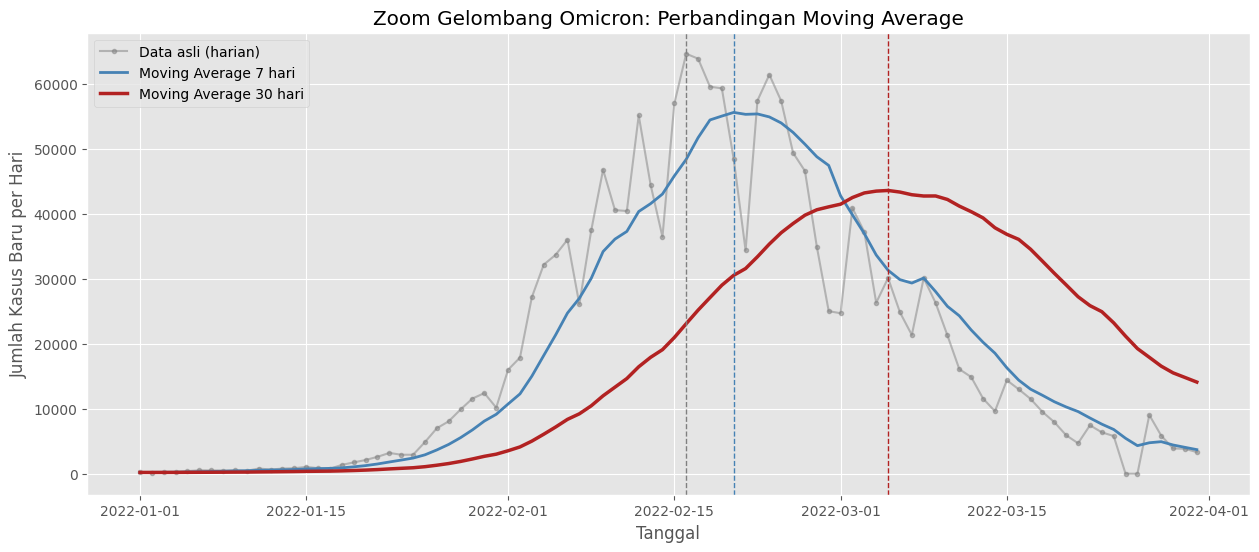

In [ ]:
zoom_omicron = df_idn.loc['2022-01-01':'2022-03-31']

plt.figure(figsize=(15, 6))

plt.plot(zoom_omicron.index, zoom_omicron['Kasus Baru'], color='gray',
         alpha=0.5, marker='.', label='Data asli (harian)')
plt.plot(zoom_omicron.index, zoom_omicron['MA 7 Hari'], color='steelblue',
         linewidth=2, label='Moving Average 7 hari')
plt.plot(zoom_omicron.index, zoom_omicron['MA 30 Hari'], color='firebrick',
         linewidth=2.5, label='Moving Average 30 hari')

# Tandai titik puncak setiap kurva
for col, color in [('Kasus Baru', 'gray'), ('MA 7 Hari', 'steelblue'),
                   ('MA 30 Hari', 'firebrick')]:
    plt.axvline(zoom_omicron[col].idxmax(), color=color,
                linestyle='--', linewidth=1)

plt.title('Zoom Gelombang Omicron: Perbandingan Moving Average')
plt.ylabel('Jumlah Kasus Baru per Hari')
plt.xlabel('Tanggal')
plt.legend(loc='upper left')
plt.show()

In [ ]:
# Summary gelombang Delta
summary_delta = pd.DataFrame({
    'Tanggal Puncak': [zoom_delta[c].idxmax().date() for c in ['Kasus Baru', 'MA 7 Hari', 'MA 30 Hari']],
    'Nilai Puncak': [int(zoom_delta[c].max()) for c in ['Kasus Baru', 'MA 7 Hari', 'MA 30 Hari']],
    'Jumlah NaN di Awal': [df_idn[c].isnull().sum() for c in ['Kasus Baru', 'MA 7 Hari', 'MA 30 Hari']],
    'Rata-rata Perubahan Harian': [int(df_idn[c].diff().abs().mean()) for c in ['Kasus Baru', 'MA 7 Hari', 'MA 30 Hari']],
}, index=['Data asli', 'MA 7 hari', 'MA 30 hari'])

summary_delta

,Tanggal Puncak,Nilai Puncak,Jumlah NaN di Awal,Rata-rata Perubahan Harian
Data asli,2021-07-15,56757,0,988
MA 7 hari,2021-07-18,50039,6,259
MA 30 hari,2021-08-06,40948,29,189


In [ ]:
# Summary gelombang Omicron
summary_omicron = pd.DataFrame({
    'Tanggal Puncak': [zoom_omicron[c].idxmax().date() for c in ['Kasus Baru', 'MA 7 Hari', 'MA 30 Hari']],
    'Nilai Puncak': [int(zoom_omicron[c].max()) for c in ['Kasus Baru', 'MA 7 Hari', 'MA 30 Hari']],
    'Jumlah NaN di Awal': [df_idn[c].isnull().sum() for c in ['Kasus Baru', 'MA 7 Hari', 'MA 30 Hari']],
    'Rata-rata Perubahan Harian': [int(df_idn[c].diff().abs().mean()) for c in ['Kasus Baru', 'MA 7 Hari', 'MA 30 Hari']],
}, index=['Data asli', 'MA 7 hari', 'MA 30 hari'])

summary_omicron

,Tanggal Puncak,Nilai Puncak,Jumlah NaN di Awal,Rata-rata Perubahan Harian
Data asli,2022-02-16,64718,0,988
MA 7 hari,2022-02-20,55675,6,259
MA 30 hari,2022-03-05,43645,29,189


### Efek Ukuran Window dan Trade-off-nya

Berdasarkan hasil summary, terdapat tiga pengaruh utama:

1\. Kehalusan kurva: Semakin besar window, semakin halus kurva. Rata-rata perubahan harian turun dari 988 (data asli), 259 (MA 7 hari), menjadi 189 (MA 30 hari).

2\. Kehilangan data: MA 7 hari menghasilkan 6 NaN, sedangkan MA 30 hari menghasilkan 29 NaN karena membutuhkan lebih banyak data awal.

3\. Pergeseran puncak: Pada Delta, puncak data asli 56.757 kasus (15 Juli 2021) turun menjadi 40.948 kasus (6 Agustus) pada MA 30 hari. Pada Omicron, puncak 64.718 kasus (16 Februari 2022) turun menjadi 43.645 kasus (5 Maret) pada MA 30 hari.

Kesimpulan: MA 7 hari lebih cocok untuk melihat tren utama karena tetap mempertahankan posisi puncak dengan pergeseran kecil. MA 30 hari lebih sesuai untuk melihat gambaran umum gelombang karena lebih halus, tetapi menghasilkan puncak yang lebih rendah dan terlambat.

### Ringkasan angka per gelombang (untuk insight)

In [ ]:
waves = {
    'Awal 2021': ('2020-12-01', '2021-03-31'),
    'Delta':     ('2021-06-01', '2021-09-30'),
    'Omicron':   ('2022-01-01', '2022-04-30'),
    'Pertengahan 2022': ('2022-06-01', '2022-09-30'),
    'Akhir 2022': ('2022-10-01', '2022-12-31'),
}

df_idn['MA7 Kematian'] = df_idn['Kematian Baru'].rolling(7).mean()

rows = []
for name, (start, end) in waves.items():
    w = df_idn.loc[start:end]
    rows.append([name,
                 w['MA 7 Hari'].idxmax().date(), int(w['MA 7 Hari'].max()),
                 w['MA7 Kematian'].idxmax().date(), int(w['MA7 Kematian'].max()),
                 round(w['Kematian Baru'].sum() / w['Kasus Baru'].sum() * 100, 2)])

df_waves = pd.DataFrame(rows, columns=['Gelombang', 'Puncak Kasus (MA7)', 'Kasus/hari',
                                       'Puncak Kematian (MA7)', 'Kematian/hari', 'Kematian per 100 Kasus (%)'])
df_waves.set_index('Gelombang', inplace=True)
df_waves

,Puncak Kasus (MA7),Kasus/hari,Puncak Kematian (MA7),Kematian/hari,Kematian per 100 Kasus (%)
Gelombang,,,,,
Awal 2021,2021-02-01,12864,2021-01-31,309,2.46
Delta,2021-07-18,50039,2021-08-02,1789,3.82
Omicron,2022-02-20,55675,2022-03-08,310,0.68
Pertengahan 2022,2022-08-09,5579,2022-08-20,22,0.40
Akhir 2022,2022-11-20,6694,2022-12-02,45,0.87


#Analisisi Tren: Exponential Fit

Exponential fit digunakan untuk mengukur seberapa cepat kasus naik pada fase awal gelombang. Data MA 7 hari di-log terlebih dahulu, lalu dicocokkan dengan garis lurus menggunakan np.polyfit. Dari laju pertumbuhan yang didapat, doubling time (waktu kasus berlipat dua) dihitung dengan rumus ln(2) / laju. Fitting hanya dilakukan pada fase naik, yaitu 1 Juni–18 Juli 2021 untuk Delta dan 25 Desember 2021–20 Februari 2022 untuk Omicron.

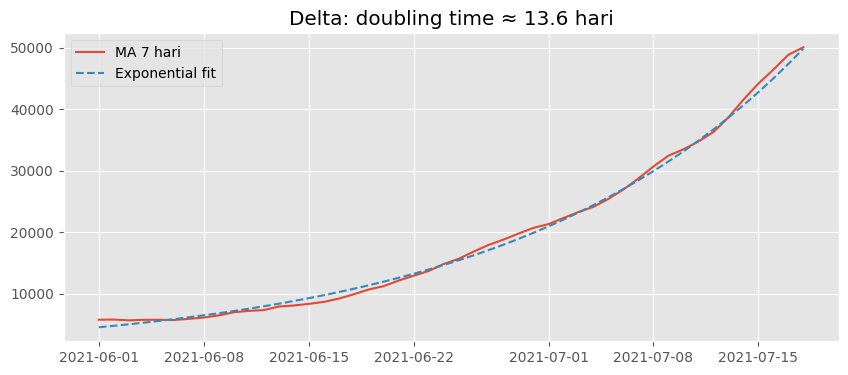

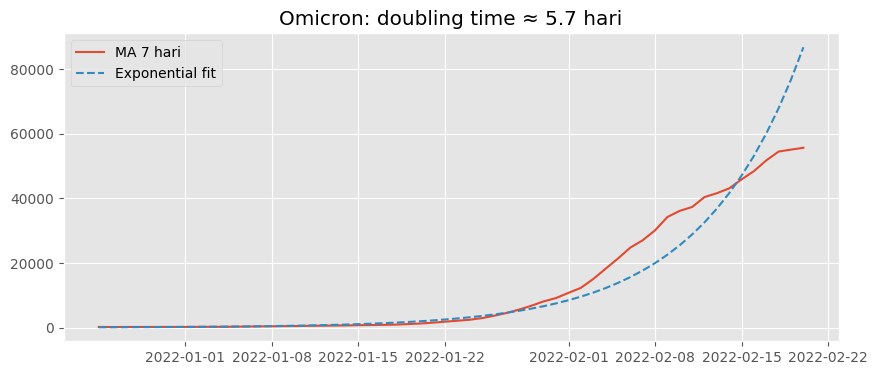

In [ ]:
def exp_fit(start, end):
    w = df_idn.loc[start:end, 'MA 7 Hari']
    x = np.arange(len(w))
    # polyfit pada log(y) -> garis lurus: log(y) = laju*x + c
    laju, c = np.polyfit(x, np.log(w.values), 1)
    fit = np.exp(c) * np.exp(laju * x)      # kembalikan ke skala asli
    doubling = np.log(2) / laju             # waktu kasus berlipat dua (hari)
    return w.index, w.values, fit, doubling

for nama, (s, e) in {'Delta': ('2021-06-01', '2021-07-18'),
                     'Omicron': ('2021-12-25', '2022-02-20')}.items():
    idx, asli, fit, dt = exp_fit(s, e)
    plt.figure(figsize=(10, 4))
    plt.plot(idx, asli, label='MA 7 hari')
    plt.plot(idx, fit, '--', label='Exponential fit')
    plt.title(f'{nama}: doubling time ≈ {dt:.1f} hari')
    plt.legend()
    plt.show()

Doubling time gelombang Delta sekitar 13,6 hari, sedangkan Omicron sekitar 5,7 hari. Artinya kasus Omicron berlipat dua lebih dari dua kali lebih cepat dibandingkan Delta. Garis fit Delta mengikuti data dengan sangat baik karena kenaikannya relatif stabil. Pada Omicron, garis fit cocok di awal tetapi melampaui data di bagian akhir, karena kenaikan melambat saat mendekati puncak. Jadi, exponential fit cocok untuk fase awal kenaikan gelombang, bukan untuk seluruh gelombang.

# Identifikasi Komponen Time Series <a id="18"></a>

Berdasarkan grafik yang tersedia, komponen time series yang teramati adalah:

**1. Trend (arah jangka panjang)**

Tren kasus harian meningkat dari Maret 2020 hingga mencapai puncak Omicron pada Februari 2022, kemudian menurun dan bertahan pada level rendah hingga awal 2023. Pola ini terlihat jelas pada MA 30 hari dan menunjukkan bentuk naik–puncak–turun.

**2. Seasonality (pola berulang periodik)**

Pola mingguan terlihat konsisten pada 2020–2022, dengan kasus terendah pada Senin dan Minggu, serta tertinggi pada Rabu–Jumat. Pola ini kemungkinan dipengaruhi siklus pemeriksaan dan pelaporan. Sebaliknya, pola musiman tahunan tidak terlihat konsisten pada calendar heatmap.

**3. Cyclic (fluktuasi jangka panjang)**

Kasus membentuk beberapa gelombang, yaitu awal 2021, Juli 2021 (Delta), Februari 2022 (Omicron), Agustus 2022, dan November 2022. Jarak serta tinggi puncaknya berbeda-beda sehingga termasuk pola siklik, bukan musiman.

**4. Noise (variasi acak)**

Fluktuasi terlihat pada data harian asli, misalnya 2 September 2021 tercatat 0 kasus, kemudian meningkat menjadi 16.752 kasus pada 3 September 2021. Hal ini kemungkinan disebabkan penumpukan laporan. Fluktuasi tersebut dapat dihaluskan menggunakan moving average.

# Insight & Interpretasi <a id="20"></a>


**1. Gelombang Delta dan Omicron mendominasi pandemi.**  
Kasus bulanan mencapai sekitar 1,2 juta pada Juli 2021 (Delta) dan Februari 2022 (Omicron). Puncak harian Omicron lebih tinggi, yaitu 64.718 kasus (16 Februari 2022), dibandingkan Delta sebanyak 56.757 kasus (15 Juli 2021).

**2. Omicron memiliki peningkatan kasus lebih cepat, sedangkan kematian lebih tinggi saat Delta.**
Berdasarkan exponential fit, doubling time Omicron sekitar 6 hari, dibandingkan Delta sekitar 14 hari. Namun, puncak kematian harian (MA 7) saat Delta mencapai 1.789, sedangkan Omicron sekitar 310. Kematian per 100 kasus juga turun dari 3,8% menjadi 0,7%.

**3. Kematian meningkat paling tajam pada 2021.**  
Kematian kumulatif naik dari 50 ribu (28 Mei 2021) menjadi 100 ribu (4 Agustus 2021) dalam sekitar dua bulan. Peningkatan hingga 150 ribu baru tercapai pada 6 Maret 2022.

**4. Terdapat pola pelaporan mingguan.**  
Rata-rata kasus pada Senin (4.816) sekitar 28% lebih rendah dibandingkan Kamis (6.679). Karena itu, MA 7 hari lebih tepat digunakan untuk membaca tren daripada angka harian saja.

**5. Ukuran moving average memengaruhi hasil analisis.**  
MA 30 hari lebih halus, tetapi puncak Delta menjadi 40.948 kasus dan bergeser ke 6 Agustus 2021, dibandingkan data asli sebesar 56.757 kasus pada 15 Juli 2021. MA 7 hari lebih responsif, sedangkan MA 30 hari cocok untuk melihat tren jangka panjang.

**6. Vietnam melampaui Indonesia dalam kasus kumulatif.**  
Vietnam menyalip Indonesia pada 12 Maret 2022. Pada akhir periode, kasus kumulatif Vietnam mencapai sekitar 11,5 juta, sedangkan Indonesia 6,74 juta. Angka ini menggambarkan kasus terdeteksi dan dipengaruhi kapasitas pengujian masing-masing negara.

**7. Gelombang setelah Omicron relatif lebih kecil.**  
Puncak MA 7 pada Agustus dan November 2022 hanya sekitar 5,6 ribu dan 6,7 ribu kasus per hari. Pada 9 Maret 2023, kasus baru tercatat 307 per hari.

**8. Terdapat anomali pelaporan harian.**  
Pada 2 September 2021 tercatat 0 kasus, kemudian meningkat menjadi 16.752 kasus pada 3 September. Hal ini kemungkinan disebabkan keterlambatan atau penumpukan pelaporan, bukan perubahan penularan secara langsung.

## Kendala
- Data COVID-19 JHU CSSE yang digunakan mencakup periode 1 Maret 2020 sampai 9 Maret 2023, sehingga perkembangan kasus setelah tanggal tersebut belum dapat dianalisis.
- Jumlah kasus yang tercatat dipengaruhi oleh kapasitas pemeriksaan dan sistem pelaporan masing-masing negara.
- Dataset tidak menyediakan informasi varian virus secara langsung, sehingga identifikasi periode Delta dan Omicron didasarkan pada konteks waktu.

## Saran Pengembangan
- Membandingkan kasus per satu juta penduduk agar lebih proporsional antarnegara.
- Menambahkan data vaksinasi, jumlah tes, dan positivity rate.
- Menggunakan metode peramalan seperti ARIMA atau Prophet untuk analisis lanjutan.



# Daftar Pustaka

[1] E. Dong, H. Du, and L. Gardner, “An interactive web-based dashboard to track COVID-19 in real time,” The Lancet Infectious Diseases, vol. 20, no. 5, pp. 533–534, 2020. [Online]. Available: https://github.com/CSSEGISandData/COVID-19.

[2] Telkom University, “Materi Kuliah CAK4XBB3 Visualisasi Data: 2_Visualization_Tools_1, 3_Visualization_Tools_2, 4_Exploratory_Data_Analysis, dan 6_Visualization_in_Finance.” Materi perkuliahan.

[3] pandas Development Team, “Time series / date functionality,” pandas Documentation. [Online]. Available: https://pandas.pydata.org/docs/user_guide/timeseries.html.

[4] NumPy Developers, “numpy.polyfit,” NumPy Documentation. [Online]. Available: https://numpy.org/doc/stable/reference/generated/numpy.polyfit.html.